In [1]:
import gudhi
import modules as mod
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib

- example from ali (make it into a "finite" rectangle module") 
- make rectangles open to the right, top in code 
- 

### To do : add visualization of modules
https://www.geeksforgeeks.org/matplotlib-patches-rectangle-in-python/ 

In [2]:
rect_m1 = mod.Rectangle((0,-1),(7,6),1)
rect_m2 = mod.Rectangle((0,3),(7,10),1)
M = mod.RectangleModule([rect_m1,rect_m2])
rect_n1 = mod.Rectangle((0,-1),(7,10),1)
rect_n2 = mod.Rectangle((0,3),(7,6),1)
N= mod.RectangleModule([rect_n1,rect_n2])

In [3]:
L = mod.Line((1,1),(0,0))
L_low = mod.Line((1,1),(1/2,-1/2))
L_up = mod.line_through_2points((0,3),(7,10))
L_up.b

(-1.5, 1.5)

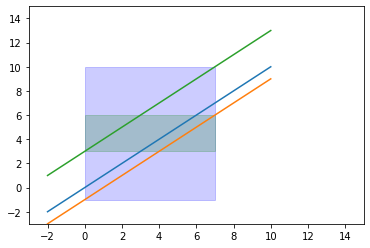

In [4]:
fig = plt.figure()
ax = fig.add_subplot(111)

a1 = rect_n1.bottom_left 
h1= rect_n1.top_right[0]- a1[0]
v1= rect_n1.top_right[1]- a1[1]
 
a2 = rect_n2.bottom_left 
h2= rect_n2.top_right[0]- a2[0]
v2= rect_n2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

x = np.linspace(-2, 10, 1000)
plt.plot(x, x + 0, linestyle='solid') ##L 
plt.plot(x, x -1, linestyle='solid') 
plt.plot(x, x + 3, linestyle='solid') 



ax.add_patch(rect1)
ax.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
  
plt.show()

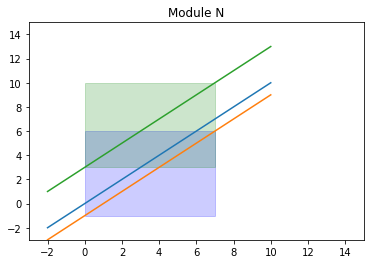

In [5]:
fig = plt.figure()
ax = fig.add_subplot(111)
## rectangles 
a1 = rect_m1.bottom_left 
h1= rect_m1.top_right[0]- a1[0]
v1= rect_m1.top_right[1]- a1[1]
a2 = rect_m2.bottom_left 
h2= rect_m2.top_right[0]- a2[0]
v2= rect_m2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-2, 10, 1000)
plt.plot(x, x + 0, linestyle='solid') ##L 
plt.plot(x, x -1, linestyle='solid') 
plt.plot(x, x + 3, linestyle='solid') 

ax.add_patch(rect1)
ax.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])

plt.title('Module N')  
plt.show()

Text(0.5, 1.0, 'Module N')

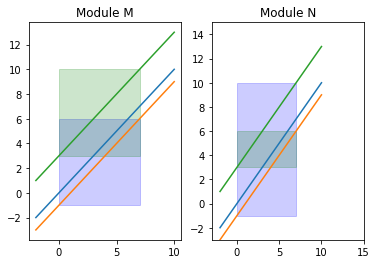

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2)
#fig.suptitle('Horizontally stacked subplots')
a1 = rect_m1.bottom_left 
h1= rect_m1.top_right[0]- a1[0]
v1= rect_m1.top_right[1]- a1[1]
a2 = rect_m2.bottom_left 
h2= rect_m2.top_right[0]- a2[0]
v2= rect_m2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

x = np.linspace(-2, 10, 1000)
ax1.plot(x, x + 0, linestyle='solid') ##L 
ax1.plot(x, x -1, linestyle='solid')  ##L_low
ax1.plot(x, x + 3, linestyle='solid') ##L_up



ax1.add_patch(rect1)
ax1.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
ax1.set_title('Module M')

###
a1 = rect_n1.bottom_left 
h1= rect_n1.top_right[0]- a1[0]
v1= rect_n1.top_right[1]- a1[1]
a2 = rect_n2.bottom_left 
h2= rect_n2.top_right[0]- a2[0]
v2= rect_n2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-2, 10, 1000)
ax2.plot(x, x + 0, linestyle='solid') ##L 
ax2.plot(x, x -1, linestyle='solid') 
ax2.plot(x, x + 3, linestyle='solid') 

ax2.add_patch(rect1)
ax2.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
ax2.set_title('Module N')

In [21]:
[inter_m1, param_m1] = rect_m1.find_intersection(L_low)
print(inter_m1)
[inter_m2, param_m2] = rect_m2.find_intersection(L_low)
print(inter_m2)
dgmM = M.compute_barcode(L_low)
print(dgmM)

[(0.0, -1)]
[(4.0, 3), (7, 6.0)]
[[3.5, 6.5]]


In [14]:
## Family of lines in same equivalence class 
n = 100 ## number of points in interval 
t = 2/n 
Lines = []
wbd=[]
x=[]
for i in range(n+1):
    b= i*t
    x.append(-1.5+b)
    #print(b)
    line = mod.Line((1,1),(-1.5+b,1.5-b))
    print(line.b)
    #print(line.m)
    #print(line.b)
    Lines.append(line)
    d = mod.compute_weighted_bottleneck(M,N,line)
    wbd.append(d)
    print(d)
    #print('------')
    

(-1.5, 1.5)
2.202001918764775e-308
(-1.48, 1.48)
0.040000000000000036
(-1.46, 1.46)
0.08000000000000006
(-1.44, 1.44)
0.12000000000000009
(-1.42, 1.42)
0.16000000000000014
(-1.4, 1.4)
0.20000000000000018
(-1.38, 1.38)
0.2400000000000002
(-1.3599999999999999, 1.3599999999999999)
0.28000000000000025
(-1.34, 1.34)
0.3199999999999998
(-1.32, 1.32)
0.3599999999999998
(-1.3, 1.3)
0.39999999999999986
(-1.28, 1.28)
0.4399999999999999
(-1.26, 1.26)
0.48
(-1.24, 1.24)
0.52
(-1.22, 1.22)
0.56
(-1.2, 1.2)
0.6
(-1.18, 1.18)
0.64
(-1.16, 1.16)
0.6800000000000002
(-1.1400000000000001, 1.1400000000000001)
0.7199999999999998
(-1.12, 1.12)
0.7599999999999998
(-1.1, 1.1)
0.7999999999999998
(-1.08, 1.08)
0.8399999999999999
(-1.06, 1.06)
0.8799999999999999
(-1.04, 1.04)
0.9199999999999999
(-1.02, 1.02)
0.96
(-1.0, 1.0)
1.0
(-0.98, 0.98)
1.04
(-0.96, 0.96)
1.08
(-0.94, 0.94)
1.1199999999999999
(-0.92, 0.92)
1.1600000000000001
(-0.9, 0.9)
1.2
(-0.88, 0.88)
1.2400000000000002
(-0.86, 0.86)
1.28
(-0.84, 0.84)


In [15]:
mod.compute_weighted_bottleneck(M,N,L)

1.0

Text(0, 0.5, 'weighted bottleneck distance')

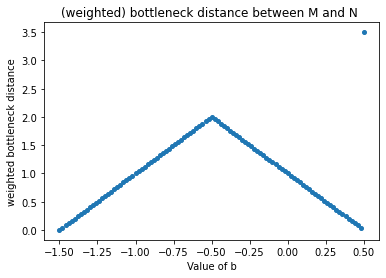

In [16]:
fig, ax = plt.subplots()
plt.plot(x, wbd, 'o',markersize = 4)
plt.title('(weighted) bottleneck distance between M and N ')
plt.xlabel('Value of b')
plt.ylabel('weighted bottleneck distance')

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2)
#fig.suptitle('Horizontally stacked subplots')
a1 = rect_n1.bottom_left 
h1= rect_n1.top_right[0]- a1[0]
v1= rect_n1.top_right[1]- a1[1]
 
a2 = rect_n2.bottom_left 
h2= rect_n2.top_right[0]- a2[0]
v2= rect_n2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

x = np.linspace(-2, 10, 1000)
ax1.plot(x, x + 0, linestyle='solid') ##L 
ax1.plot(x, x -1, linestyle='solid') 
ax1.plot(x, x + 3, linestyle='solid') 
ax1.plot(x, x + 0.75, linestyle='dashed') ## check this corresponds to change in distance 
#ax1.plot(x, x + 0.25, linestyle='dashed')
ax1.add_patch(rect1)
ax1.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
ax1.set_title('Module M')

###
a1 = rect_m1.bottom_left 
h1= rect_m1.top_right[0]- a1[0]
v1= rect_m1.top_right[1]- a1[1]
a2 = rect_m2.bottom_left 
h2= rect_m2.top_right[0]- a2[0]
v2= rect_m2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-2, 10, 1000)
ax2.plot(x, x + 0, linestyle='solid') ##L 
ax2.plot(x, x -1, linestyle='solid') 
ax2.plot(x, x + 3, linestyle='solid') 
ax2.plot(x, x + 0.75, linestyle='dashed') 

ax2.add_patch(rect1)
ax2.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
ax2.set_title('Module N')

In [9]:
wbd

[2.202001918764775e-308,
 0.040000000000000036,
 0.08000000000000006,
 0.12000000000000009,
 0.16000000000000014,
 0.20000000000000018,
 0.2400000000000002,
 0.28000000000000025,
 0.3199999999999998,
 0.3599999999999998,
 0.39999999999999986,
 0.4399999999999999,
 0.48,
 0.52,
 0.56,
 0.6,
 0.64,
 0.6800000000000002,
 0.7199999999999998,
 0.7599999999999998,
 0.7999999999999998,
 0.8399999999999999,
 0.8799999999999999,
 0.9199999999999999,
 0.96,
 1.0,
 1.04,
 1.08,
 1.1199999999999999,
 1.1600000000000001,
 1.2,
 1.2400000000000002,
 1.28,
 1.3200000000000003,
 1.3600000000000003,
 1.4000000000000004,
 1.4399999999999995,
 1.48,
 1.5199999999999998,
 1.56,
 1.5999999999999999,
 1.6400000000000001,
 1.6799999999999997,
 1.7199999999999998,
 1.7599999999999998,
 1.7999999999999998,
 1.8399999999999996,
 1.88,
 1.92,
 1.96,
 2.0,
 1.9600000000000009,
 1.92,
 1.879999999999999,
 1.8399999999999996,
 1.8000000000000007,
 1.7599999999999998,
 1.7199999999999989,
 1.6799999999999997,
 1.640